In [1]:
from pynwb import NWBHDF5IO
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

In [2]:
file_path = r"C:\Users\kianb\Projects\mouse-v1-research\data\session_757216464\session_757216464.nwb"
io=NWBHDF5IO(file_path, mode="r")
nwbfile = io.read()
#print(nwbfile.session_id)
#print(nwbfile.session_description)
#print(nwbfile.session_start_time)
#print(nwbfile.institution)

#print("Total units:", len(nwbfile.units))

print("Unit columns:", nwbfile.units.colnames)
units_df = nwbfile.units.to_dataframe()
# KEEP THIS ONE                           print(units_df.head())

io.close()

channels = pd.read_csv("../data/channels.csv")

Unit columns: ('waveform_halfwidth', 'waveform_duration', 'silhouette_score', 'nn_hit_rate', 'amplitude_cutoff', 'quality', 'spread', 'isi_violations', 'presence_ratio', 'peak_channel_id', 'nn_miss_rate', 'isolation_distance', 'PT_ratio', 'local_index', 'snr', 'velocity_below', 'd_prime', 'firing_rate', 'velocity_above', 'max_drift', 'cumulative_drift', 'repolarization_slope', 'amplitude', 'cluster_id', 'l_ratio', 'recovery_slope', 'spike_times', 'spike_amplitudes', 'waveform_mean')


In [3]:
#print(channels.head())
#print(channels.columns.to_list())

# KEEP THIS ONE                           print(channels["ecephys_structure_acronym"].value_counts())
# KEEP THIS ONE                           print(sum(channels["ecephys_structure_acronym"] == "VISp"))


merged_df = pd.merge(units_df, channels, left_on='peak_channel_id', right_on='id', how='left')
# KEEP THIS ONE                           print(len(merged_df))
# KEEP THIS ONE                           print(merged_df["ecephys_structure_acronym"].isna().sum())

# KEEP THIS ONE                           print(sum(merged_df["ecephys_structure_acronym"]=="VISp"))

visp_units = merged_df[merged_df["ecephys_structure_acronym"] == "VISp"]

In [4]:
#print(visp_units["quality"].value_counts())

#print(channels["id"].duplicated().sum())

#print(visp_units['snr'].min())
#print(visp_units['snr'].max())
#print(visp_units['snr'].mean())

good_units = visp_units[visp_units["quality"]=="good"]
noise_units = visp_units[visp_units["quality"]=="noise"]

print("goodunits:\n", good_units['snr'].min())
print(good_units['snr'].max())
print(good_units['snr'].mean())
print("noise:\n", noise_units['snr'].min())
print(noise_units['snr'].max())
print(noise_units['snr'].mean())

goodunits:
 1.00049108124222
5.47329211307827
2.3644839516769456
noise:
 0.33700857452312
5.61835770388753
1.7752212081198662


In [5]:
print("goodunits:")
print(good_units['isi_violations'].min())
print(good_units['isi_violations'].max())
print(good_units['isi_violations'].mean())
print(good_units['isi_violations'].median())
print(good_units['isi_violations'].idxmax())
print("ISI violation value of the largest: ", good_units['isi_violations'][2263])
print("SNR value of the largest: ", good_units['snr'][2263])
print("noise:")
print(noise_units['isi_violations'].median())
print(noise_units['isi_violations'].min())
print(noise_units['isi_violations'].max())
print(noise_units['isi_violations'].mean())

goodunits:
0.0
82.8486824081072
0.9082983798717026
0.126987807425889
2263
ISI violation value of the largest:  82.8486824081072
SNR value of the largest:  1.75370865713745
noise:
0.47973544628000053
0.0
1.96729411299047
0.5984237263286251


In [6]:
print(sum(good_units['isi_violations']>1))

37


In [7]:
print("good units:")
print(good_units['presence_ratio'].min())
print(good_units['presence_ratio'].max())
print(good_units['presence_ratio'].mean())
print(good_units['presence_ratio'].median())
print("noise:")
print(noise_units['presence_ratio'].median())
print(noise_units['presence_ratio'].min())
print(noise_units['presence_ratio'].max())
print(noise_units['presence_ratio'].mean())

good units:
0.03
0.99
0.9586829268292681
0.99
noise:
0.99
0.04
0.99
0.8298214285714286


In [8]:
print(sum(good_units['presence_ratio']<0.9))
print(sum(noise_units['presence_ratio']<0.9))

22
15


In [9]:
low_presence_units = visp_units[visp_units['presence_ratio']<0.9]
print(low_presence_units['firing_rate'].mean())
print(low_presence_units['firing_rate'].median())

1.076619131669533
0.0918106289871414


In [10]:
high_presence_units = visp_units[visp_units['presence_ratio']>=0.9]
print(len(low_presence_units))
print(len(high_presence_units))
print("Firing rate of neurons with Low presence ratio:")
print(low_presence_units['firing_rate'].mean())
print(low_presence_units['firing_rate'].median())
print(low_presence_units['firing_rate'].std())
print("Firing rate of neurons with High presence ratio:")
print(high_presence_units['firing_rate'].mean())
print(high_presence_units['firing_rate'].median())
print(high_presence_units['firing_rate'].std()) 

37
224
Firing rate of neurons with Low presence ratio:
1.076619131669533
0.0918106289871414
1.6966925689963348
Firing rate of neurons with High presence ratio:
4.426310342572994
2.3907633189700253
5.646261557693371


Spearman correlation coefficient:  0.4911896011263278
p-value:  2.951496053473523e-17


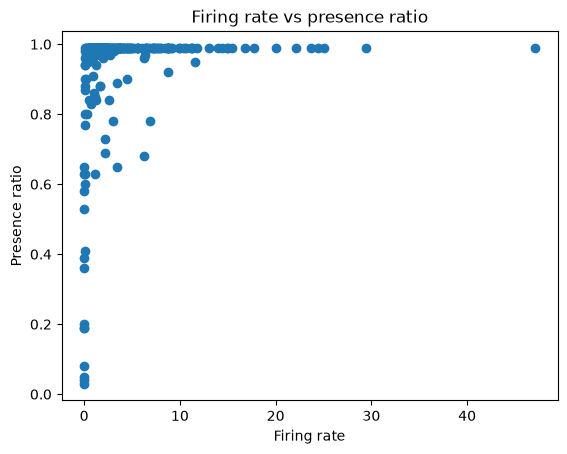

In [11]:
plt.scatter(visp_units['firing_rate'],visp_units['presence_ratio'])
plt.title("Firing rate vs presence ratio")
plt.xlabel("Firing rate")
plt.ylabel("Presence ratio")

correlation, p_value = stats.spearmanr(visp_units['firing_rate'],visp_units['presence_ratio'])
print("Spearman correlation coefficient: ", correlation)
print("p-value: ", p_value)

Text(0, 0.5, 'Presence ratio')

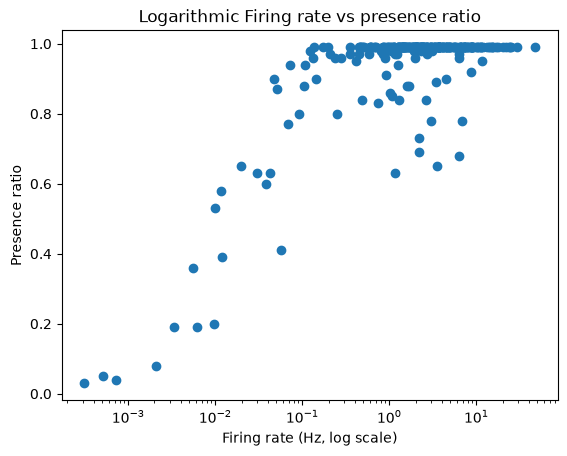

In [12]:
X = visp_units[visp_units['firing_rate']>0]
plt.scatter(X['firing_rate'], X['presence_ratio'])
plt.xscale("log")
plt.title("Logarithmic Firing rate vs presence ratio")
plt.xlabel("Firing rate (Hz, log scale)")
plt.ylabel("Presence ratio")

In [13]:
gcorrelation, gp = stats.spearmanr(good_units['firing_rate'],good_units['presence_ratio'])
ncorrelation, np = stats.spearmanr(noise_units['firing_rate'],noise_units['presence_ratio'])
print("Spearman correlation coefficient of good quality: ", gcorrelation)
print("p-value of good quality: ", gp)
print("Spearman correlation coefficient of noise: ", ncorrelation)
print("p-value of noise: ", np)

Spearman correlation coefficient of good quality:  0.4546439154823197
p-value of good quality:  7.499670069397552e-12
Spearman correlation coefficient of noise:  0.5862490827070139
p-value of noise:  2.060036035101137e-06


In [14]:
print(sum(visp_units['firing_rate'] <= 0))

0


### Relationship Between Firing Rate and Presence Ratio

Across the 261 VISp-associated units, firing rate and presence ratio showed a moderate positive correlation (Spearman ρ = 0.491, p = 2.95 × 10⁻¹⁷). The scatter plot shows that neurons with higher firing rates generally have presence ratios close to 0.99, while neurons with lower firing rates show much greater variability.

This positive relationship was also observed when analyzing good-quality units (ρ = 0.455, p = 7.50 × 10⁻¹²) and noise-labeled units (ρ = 0.586, p = 2.06 × 10⁻⁶) separately.

One possible explanation is that neurons with higher firing rates are more likely to produce at least one spike within each recording interval, resulting in higher presence ratios. Therefore, the observed relationship may partly arise from how presence ratio is calculated rather than reflecting differences in recording stability alone.

Although these results provide evidence of an association, they do not establish causation. Additional analysis would be necessary to distinguish low neuronal activity from recording instability.

All 261 VISp-associated units had positive firing rates, so no observations were excluded from the logarithmic visualization

In [15]:
print("Amplitude Cutoff for good units: ")
print(  good_units['amplitude_cutoff'].min())
print(good_units['amplitude_cutoff'].max())
print(good_units['amplitude_cutoff'].mean())
print(good_units['amplitude_cutoff'].median())
print("noise:")
print(noise_units['amplitude_cutoff'].median())
print(noise_units['amplitude_cutoff'].min())
print(noise_units['amplitude_cutoff'].max())
print(noise_units['amplitude_cutoff'].mean())

Amplitude Cutoff for good units: 
5.12886620959572e-06
0.5
0.14533440546654489
0.0339403647180357
noise:
0.5
4.90540581529943e-06
0.5
0.3899466324540138


In [16]:
print(len(visp_units[(visp_units['amplitude_cutoff'] < 0.1) & (visp_units['isi_violations'] < 0.5) & (visp_units['presence_ratio']>0.9)]))

91


In [17]:
filtered_units = visp_units[(visp_units['amplitude_cutoff'] < 0.1) & (visp_units['isi_violations'] < 0.5) & (visp_units['presence_ratio']>0.9)]
print(len(filtered_units[filtered_units['quality']=="good"]))
print(len(filtered_units[filtered_units['quality']=="noise"]))

87
4


In [18]:
print(len(visp_units[(visp_units['amplitude_cutoff'] >= 0.1)]))
print(len(visp_units[(visp_units['isi_violations'] >= 0.5)]))
print(len(visp_units[(visp_units['presence_ratio'] <= 0.9)]))

124
83
40


In [22]:
print(len(visp_units[
    (visp_units['amplitude_cutoff'] >= 0.1) &
    (visp_units['isi_violations'] >= 0.5) &
    (visp_units['presence_ratio'] <= 0.9)]))

print(len(visp_units[
    (visp_units['amplitude_cutoff'] >= 0.1) & (visp_units['isi_violations'] >= 0.5) | 
    (visp_units['amplitude_cutoff'] >= 0.1) & (visp_units['presence_ratio'] <= 0.9) |
    (visp_units['isi_violations'] >= 0.5) & (visp_units['presence_ratio'] <= 0.9)]))

print(len(visp_units[(visp_units['amplitude_cutoff'] >= 0.1)]))
print(len(visp_units[(visp_units['isi_violations'] >= 0.5)]))
print(len(visp_units[(visp_units['presence_ratio'] <= 0.9)]))

print(len(visp_units[
    (visp_units['amplitude_cutoff'] < 0.1) & 
    (visp_units['isi_violations'] < 0.5) & 
    (visp_units['presence_ratio']>0.9)]))

5
72
124
83
40
91


In [26]:
amplitude_fail = visp_units['amplitude_cutoff'] >= 0.1
isi_fail = visp_units['isi_violations'] >= 0.5
presence_fail = visp_units['presence_ratio'] <= 0.9
F=amplitude_fail.astype(int)+isi_fail.astype(int)+presence_fail.astype(int)
print(F.value_counts())

1    98
0    91
2    67
3     5
Name: count, dtype: int64
